---
---
# HYPOTHESIS TESTING

---
---

## ROADMAP: where we've been, and where we're going

* Our data is usually a **sample** $\mathcal{S}$ from a broader **population** $\mathcal{P}$, and we use a sample attribute $a(\mathcal{S})$ to **estimate** a population attribute $a(\mathcal{P})$.

* Different samples give different estimates. The **sampling distribution** describes how estimates vary from sample to sample, and **probability** lets us talk precisely about that variation.

* Last time we built **confidence intervals**: a range of *plausible* values for $a(\mathcal{P})$. Using **the bootstrap**, we could do this with just *one* sample.

Today we ask a slightly different question. Instead of *"what is the value of the population attribute?"*, we ask:

> **Someone has made a claim about the world. Are the data consistent with that claim?**

* *"This jury panel was selected at random."*
* *"This octopus can predict the outcome of soccer matches."*
* *"The average age of people aboard the Titanic was 33."*

The tool for answering these questions is called **hypothesis testing**. The central idea is one you already know how to do: **simulate what the data would look like if the claim were true, and then compare that to the data we actually have.**

---
---

## A Case of Jury Selection: *Swain v. Alabama*

> **Disclaimer:** this case is adapted from Chapter 11.1 of [Computational and Inferential Thinking](https://inferentialthinking.com/chapters/11/1/assessing-a-model/) by Adhikari, DeNero and Wagner. Feel free to consult that text for more details.

The Sixth Amendment of the United States Constitution states that, *"In all criminal prosecutions, the accused shall enjoy the right to a speedy and public trial, by an impartial jury of the State and district wherein the crime shall have been committed."*

**How does a US court put together an impartial jury?**

* First, a *jury panel* is assembled: a large group of people who *could* serve as jurors. The panel is supposed to be **representative** of the eligible population in the region.
* Then the final 12-person jury is chosen from the panel. Lawyers on both sides are allowed to remove some panelists, so the final jury can look like anything. But the *panel* should look like the community.

In 1962, Robert Swain, a Black man, was convicted in Talladega County, Alabama. He appealed his case all the way to the US Supreme Court in 1965, arguing that Black people were systematically excluded from juries in Talladega County.

**The numbers:**
* At the time, only men aged 21 or older were eligible for jury service. Among these eligible men, **26%** were Black.
* On Robert Swain's jury panel of **100** men, only **8** were Black (that is, **8%**).

In 1965, the Supreme Court reviewed the case and denied the appeal. In its ruling, the Court wrote that *"the overall percentage disparity has been small."*

**Was the Court right?** If a panel is chosen at random, we wouldn't expect to get *exactly* 26 Black panelists every time; there will be some chance variation (i.e., sample error). The question is whether 8 is the kind of number chance variation can reasonably produce.

---

### 🗣 ACTIVITY: Is 8 out of 100 "small"?

Imagine panels of 100 men were drawn *completely at random* from a population in which 26% are Black. Before we formally analyze this, write down your gut answer to these questions:
1. What's the *smallest* number of Black panelists you'd find believable on a randomly selected panel?
2. On a scale of 0 to 100, how likely do you think it is that a randomly selected panel would have 8 or fewer Black panelists?


---
---

## A Model of Random Selection

In data science, a **model** is a set of assumptions about how the data were generated. Often, those assumptions involve a chance process.

Here, the model we want to assess is:

> **The panel of 100 was selected at random from the eligible population, of whom 26% were Black.**

If this model is right, then the small number of Black panelists (8) was just bad luck: the result of ordinary sample error.

**The key insight:** we can't go back in time and re-select Robert Swain's panel. But we *can* use a computer to simulate selecting panels under the model, many many times. That will show us what panels *would* look like *if* they were selected at random. Then we can compare those simulated panels to the real one.

* If the real panel looks like a typical simulated panel, the data are *consistent* with the model.
* If the real panel looks nothing like the simulated panels, the data are *inconsistent* with the model and hence provide *evidence against* the model.

In [265]:
# Load necessary libraries
import pandas as pd
import numpy as np
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

### Simulating One Panel

Recall `np.random.choice()` from our discussion of randomness: it makes a random selection from a list of options. Previously, each option was equally likely (like `"heads"` and `"tails"`).

We can make some options more likely than others with the `p` argument, which gives the probability of selecting each option. Below, every selected panelist has a 26% chance of being `"Black"` and a 74% chance of being `"Not Black"`, and we select `size = 100` panelists.

In [266]:
groups = ["Black", "Not Black"]
eligible_proportions = [0.26, 0.74]

panel = np.random.choice(groups, size = 100, p = eligible_proportions)
panel

array(['Not Black', 'Not Black', 'Not Black', 'Not Black', 'Black',
       'Not Black', 'Black', 'Not Black', 'Not Black', 'Black', 'Black',
       'Not Black', 'Not Black', 'Black', 'Not Black', 'Not Black',
       'Not Black', 'Not Black', 'Not Black', 'Not Black', 'Black',
       'Not Black', 'Black', 'Not Black', 'Not Black', 'Black',
       'Not Black', 'Black', 'Not Black', 'Black', 'Not Black',
       'Not Black', 'Not Black', 'Not Black', 'Not Black', 'Not Black',
       'Not Black', 'Not Black', 'Not Black', 'Black', 'Not Black',
       'Not Black', 'Black', 'Black', 'Black', 'Not Black', 'Not Black',
       'Black', 'Not Black', 'Not Black', 'Not Black', 'Not Black',
       'Black', 'Not Black', 'Not Black', 'Not Black', 'Black',
       'Not Black', 'Not Black', 'Not Black', 'Not Black', 'Not Black',
       'Black', 'Not Black', 'Not Black', 'Black', 'Not Black',
       'Not Black', 'Black', 'Not Black', 'Not Black', 'Not Black',
       'Black', 'Not Black', 'Black', 'Not Bla

How many Black panelists are on this simulated panel? We use the same trick as last week: a logical statement gives `True` or `False` values, and summing count how many elements are `True`.

**Run the next two cells several times.** How much does the count bounce around? Do you ever see a count as low as 8?

In [267]:
panel = np.random.choice(groups, size = 100, p = eligible_proportions)
(panel == "Black").sum()

24

### Simulating Many Panels

As with sampling distributions and the bootstrap, one simulated panel isn't enough. We use a `for` loop to simulate $N = 10,000$ randomly selected panels and record the number of Black panelists on each.

In [268]:
# Simulate 10,000 randomly selected panels, recording the number of Black panelists on each
N = 10000
simulated_counts = []

for i in range(N):
    panel = np.random.choice(groups, size = 100, p = eligible_proportions)
    count = (panel == "Black").sum()
    simulated_counts.append(count)

simulated_counts = pd.Series(simulated_counts)

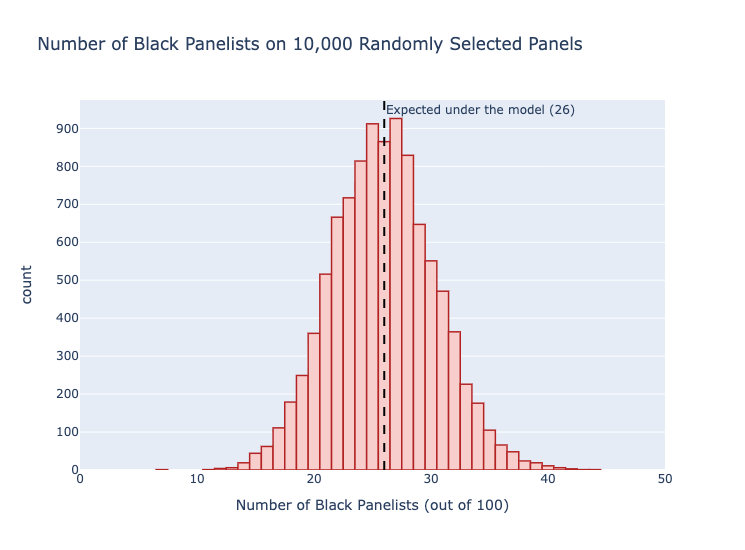

In [269]:
# Visualize the simulated counts
fig = px.histogram(simulated_counts,
                   title = "Number of Black Panelists on 10,000 Randomly Selected Panels",
                   labels = {"value":"Number of Black Panelists (out of 100)"},
                   range_x = [0, 50],
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC",
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

fig.add_vline(x = 26,
              line_width = 2,
              line_dash = "dash",
              line_color = "black",
              annotation_text = "Expected under the model (26)",
              annotation_position = "top right")

**What does this histogram tell us?**

* This is what the **model of random selection predicts**. If panels really were chosen at random, these are the kinds of counts we'd see.
* The counts are centered around 26, as we'd expect: 26% of 100 is 26.
* There's variation (i.e., sample error), but most simulated panels had somewhere between roughly 15 and 40 Black panelists.

Now let's add the real data: Robert Swain's panel had **8** Black panelists.

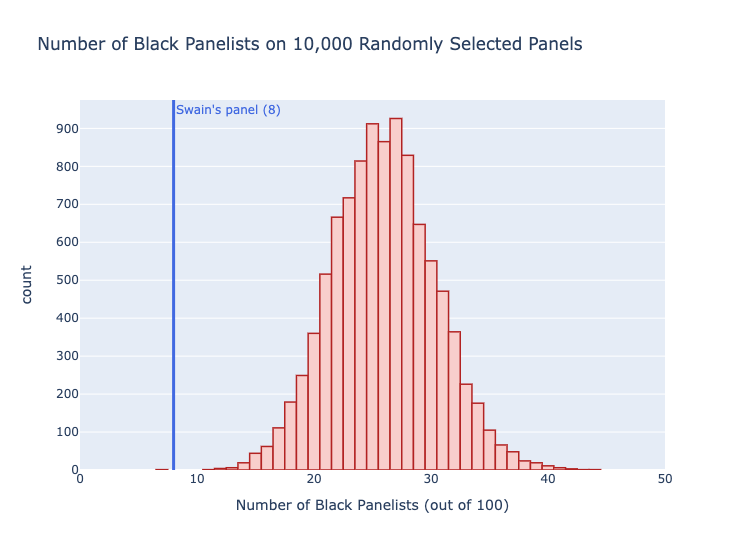

In [270]:
observed_count = 8

fig = px.histogram(simulated_counts,
                   title = "Number of Black Panelists on 10,000 Randomly Selected Panels",
                   labels = {"value":"Number of Black Panelists (out of 100)"},
                   range_x = [0, 50],
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC",
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

fig.add_vline(x = observed_count,
              line_width = 3,
              line_dash = "solid",
              line_color = "royalblue",
              annotation_text = "Swain's panel (8)",
              annotation_position = "top right",
              annotation_font_color = "royalblue")

### Comparing the Claim and the Data

The observed count of 8 is **far out in the left tail**, well away from anything the simulation typically produced.

We can make this precise with the relative frequency definition of probability. **In what proportion of the simulated panels were there 8 or fewer Black panelists?**

In [271]:
(simulated_counts <= observed_count).mean()

0.0001

Most likely you got **0** (or something extremely close to it). Out of 10,000 randomly selected panels, essentially *none* had as few as 8 Black panelists.

* This doesn't mean it's *impossible*. It means it's rarer than about 1 in 10,000. (Using probability tools beyond this course, the exact probability is about **0.000005**, or roughly **5 in a million**.)
* Go back to your answers from the earlier activity. How did your gut compare to the simulation?

**Conclusion of the data analysis:**

While it's *possible* that a randomly selected panel could have had only 8 Black panelists, our simulation shows it is *extremely unlikely*. The observed data are very inconsistent with the model. And when data and a model disagree, it's the model we should doubt: the data are real, the model is just a set of assumptions.

> **The most reasonable conclusion is that the panel was *not* selected at random from the eligible population.** Contrary to the Court's opinion, the difference between 26% and 8% is not small enough to be explained by chance. Jury panel selection was racially biased.

---
---

## The Logic of Hypothesis Testing

What we just did is called a **hypothesis test**. Let's name each of the steps so we can apply the same reasoning to *any* problem.

**Step 1. State the null hypothesis.** The **null hypothesis** $H_0$ is the claim being put to the test. It's the baseline assumption about the world that we're interested in disproving. Importantly, it has to be specific enough that we can *simulate data under it*.
* Swain: $H_0$: the panel was selected at random from a population that is 26% Black. In terms of population attributes: 
    * $H_0$: the proportion of Black people in the population the panel was drawn from is 0.26.
    * $H_0: a(\mathcal{P})=0.26$

**Step 2. State the alternative hypothesis.** The **alternative hypothesis** $H_A$ is the competing (complementary) claim, usually the one the investigator suspects is true.
* Swain: $H_A$: the selection process *under-represented* Black people. In terms of population attributes: 
    * $H_A$: the proportion of Black people in the population the panel was drawn from is *less than* 0.26.
    * $H_A: a(\mathcal{P})<0.26$

**Step 3. Choose a test statistic.** The **test statistic** is a number calculated from the data that helps us decide between $H_0$ and $H_A$. We need to know which values are consistent with $H_A$. 
* Swain: the number of Black panelists. *Small* values are consistent with $H_A$.

**Step 4. Simulate the null distribution.** The **null distribution** is the distribution of the test statistic, *assuming $H_0$ is true*. It's a sampling distribution, but in a world where the null hypothesis holds.
* Swain: the histogram of 10,000 simulated counts.

**Step 5. Calculate the p-value.** The **p-value** is the probability, *assuming $H_0$ is true*, of getting a test statistic **at least as extreme** as the one we observed (where "extreme" means "in the direction consistent with $H_A$").
* Swain: the proportion of simulated counts $\le 8$, which was about 0.

**Step 6. Make a conclusion.** A *small* p-value means our data would be very surprising if $H_0$ were true. That's evidence against $H_0$, and we **reject the null hypothesis**. A large p-value means the data are consistent with $H_0$, and we **fail to reject the null hypothesis**.
* Swain: the p-value is tiny, so we reject $H_0$. The data provide strong evidence that the panel was not selected at random.

---

### 🗣 ACTIVITY: Hypothesis testing in the courtroom

Hypothesis testing is a lot like a criminal trial. Discuss with your neighbours:

1. In a trial, the defendant is *presumed innocent* until proven guilty. Which of "innocent" or "guilty" plays the role of $H_0$? Which plays the role of $H_A$?
2. What plays the role of the *data*? What plays the role of a *small p-value*?
3. A jury's verdict is either *"guilty"* or *"not guilty"*; it is never *"innocent"*. Why? How does this relate to saying *"fail to reject $H_0$"* rather than *"accept $H_0$"*?

<details>
<summary><b>Discussion Notes</b></summary>

* $H_0$: the defendant is innocent. $H_A$: the defendant is guilty. We start by *assuming* $H_0$ and ask whether the evidence is strong enough to abandon that assumption.
* The evidence presented at trial is the data. Evidence that would be *very hard to explain if the defendant were innocent* is like a small p-value. "Beyond a reasonable doubt" is like a threshold for how small the p-value must be.
* "Not guilty" means *the evidence wasn't strong enough to convict*, not that the defendant was proven innocent. Likewise, a large p-value means *the data weren't strong enough to reject $H_0$*. It does **not** prove $H_0$ is true.

</details>

---

### Significance Levels: How small is "small"? 

**The p-value measures the strength of evidence against $H_0$.** 

* It gives us information about how inconsistent the data are with $H_0$.
* The smaller the p-value, the more evidence we have against $H_0$.
* The larger the p-value, the less evidence we have against $H_0$.

To make a decision we need a cutoff. The cutoff is called the **significance level**, denoted $\alpha$ (the Greek letter "alpha").

* If the p-value $\le \alpha$: reject $H_0$. We say the result is **statistically significant**.
* If the p-value $> \alpha$: fail to reject $H_0$.

The most common choice is $\alpha = 0.05$, but this is a *convention*, not a law of nature. 
* Sometimes stricter levels like $\alpha = 0.01$ are used when the consequences of a wrong rejection are serious. 
* It's good practice to report the p-value itself, not just "significant" or "not significant", so readers can judge the strength of evidence for themselves.

### P-value Misconceptions

P-values are among the most misunderstood numbers in science. Keep these in mind:

* ❌ **The p-value is NOT the probability that $H_0$ is true.** It's the probability of data *as extreme as ours*, calculated *assuming* $H_0$ is true.
* ❌ **A large p-value does NOT prove $H_0$ is true.** It only says the data are consistent with it (remember: "not guilty" $\neq$ "innocent").
* ❌ **A small p-value does NOT mean the effect is large or important.** With enough data, even tiny, unimportant differences can produce small p-values. Statistical significance is not the same thing as *practical* significance.

---
---

## 💻 ACTIVITY: Paul the Psychic Octopus

During the 2010 FIFA World Cup, an octopus named [Paul](https://en.wikipedia.org/wiki/Paul_the_Octopus), living at an aquarium in Oberhausen, Germany, became an international celebrity. Before each match, Paul was shown two boxes of food, each marked with one team's flag. Whichever box Paul ate from first was declared his "prediction."

<div style="text-align: center;">
<img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/8/8c/Paul_the_Octopus.jpg/500px-Paul_the_Octopus.jpg?utm_source=en.wikipedia.org&utm_campaign=parser" alt="Paul" width="300"/>
</div>

[Image Source](https://en.wikipedia.org/wiki/Paul_the_Octopus)

Paul predicted the winner of **all 8 matches** he was asked about (Germany's seven matches, plus the final), a perfect 8 for 8.

**Is Paul psychic?** Let's test it.

* The *null hypothesis* is that Paul is just guessing and each prediction is correct with probability 0.5, like a coin flip. If we define the population attribute $a(\mathcal{P})$ as the probability he guesses correctly, we can state this hypothesis as: $$H_0: a(\mathcal{P})=0.5$$
* The *alternative hypothesis* is that Paul does better than random guessing: $$H_A: a(\mathcal{P})>0.5$$
* The *test statistic* could simply be the *sample proportion* of correct predictions: $a(\mathcal{S})$. 
   
    * *Large* values are consistent with $H_A$.

**Your tasks:**
1. Simulate one "tournament" of 8 guesses under $H_0$ and count how many are correct. (*Hint:* use `np.random.choice()` with the options `["correct", "incorrect"]`.)
2. Use a `for` loop to simulate $N = 10,000$ tournaments, recording the number correct in each. Plot the null distribution.
3. Calculate the p-value. Would you reject $H_0$ at the $\alpha = 0.05$ significance level?

In [272]:
# 1. Simulate one tournament of 8 guesses

In [273]:
# 2. Many tournaments

In [274]:
# 3. Calculate the p-value

<details>
<summary><b>Show Solution</b></summary>

```python
# 1. One tournament
guesses = np.random.choice(["correct", "wrong"], size = 8, p = [0.5, 0.5])
(guesses == "correct").mean()

# 2. Many tournaments
N = 10000
simulated_correct = []
for i in range(N):
    guesses = np.random.choice(["correct", "wrong"], size = 8, p = [0.5, 0.5])
    simulated_correct.append((guesses == "correct").mean())
simulated_correct = pd.Series(simulated_correct)

fig = px.histogram(simulated_correct,
                   title = "Null Distribution: Proportion of Correct Guesses out of 8",
                   labels = {"value":"Proportion Correct"},
                   height = 500)
fig.update_traces(showlegend = False, marker_color = "#F8CECC",
                  marker_line_color = "firebrick", marker_line_width = 1.5)
fig.add_vline(x = 1, line_width = 3, line_color = "royalblue",
              annotation_text = "Paul (1)", annotation_font_color = "royalblue")

# 3. p-value: proportion of simulated tournaments with 8 (or more) correct
(simulated_correct >= 1).mean()
```

The p-value is about 0.004 (the exact value is $0.5^8 = 1/256 \approx 0.0039$). This is well below 0.05, so we reject $H_0$...

**...but is Paul really psychic?** See the discussion below.

</details>

---

### 🗣 Discussion: Should we believe Paul is psychic?

Our hypothesis test says that a guessing octopus would go 8 for 8 only about 4 times in 1000. But does this really mean Paul is psychic?

Run the cell below. It simulates **1000 animals**, every one of them just guessing, each predicting the same 8 matches. How many of them turn out to be "perfect psychics"?

In [275]:
# 1000 animals, each guessing 8 matches at random
num_animals = 1000
is_perfect = []

for animal in range(num_animals):
    guesses = np.random.choice(["correct", "wrong"], size = 8, p = [0.5, 0.5])
    is_perfect.append((guesses == "correct").mean() == 1)   # True if this animal got all 8 right

print(f"Number of 'psychic' animals (out of {num_animals} guessers): {sum(is_perfect)}")

Number of 'psychic' animals (out of 1000 guessers): 4


Even when *every single animal is guessing*, we typically end up with a few perfect predictors. So, perhaps Paul just got lucky. Lots of people (and maybe animals) were making predictions about the 2010 World Cup, but Paul's story rose to the fore simply *because* he was lucky.

**Note:** a p-value is only meaningful if you didn't go hunting for it. If you run many tests (or look at many octopuses) and only report the most surprising one, small p-values will show up by chance alone. This is a major issue in science, sometimes called **p-hacking** or the **multiple testing problem**.

<div style="text-align: center;">
<img src="https://imgs.xkcd.com/comics/significant.png" alt="jelly-beans" width="500"/>
</div>

[Image Source](https://xkcd.com/882/)

---
---

## One-Sample Hypothesis Tests with the Bootstrap

In the Swain and Paul examples, the null hypothesis told us *exactly* how to simulate data:
* draw panelists with probabilities 0.26 and 0.74, or
* make guesses with probabilities 0.5 and 0.5.

But often a null hypothesis only specifies *one attribute* of the population, like its mean, and says nothing about the rest of the distribution (its spread, its shape, etc.). For instance:

> *Suppose a museum exhibit claims that the average age of everyone aboard the Titanic was 33 years.*

To test this claim, we'd want to simulate samples from a population whose mean age is 33. But what would such a population look like? We don't have it. **We only have one sample.**

This should sound familiar: it's the same problem we faced with confidence intervals. And the solution is the same: **the bootstrap**.

### The Data: Titanic

As in previous lectures, let's pretend we don't have the full Titanic passenger list. Instead, we have a simple random sample of $n=100$ people who were aboard. (We use `random_state` so that we all get the same sample.)

In [276]:
# Read in the data
titanic = pd.read_csv("https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/titanic_passenger_info.csv")

# Take one sample of size n=100
S = titanic.sample(n = 100, random_state = 2026)

observed_mean = S["age"].mean()
print(f"Observed average age in our sample: {observed_mean}")

Observed average age in our sample: 29.404040404040405


Our sample average isn't 33. But we know sample averages bounce around from sample to sample, so this alone doesn't tell us much. **Is the difference between our sample average and 33 big enough to doubt the museum's claim, or could it just be sample error?**

### Steps 1–3: Hypotheses and Test Statistic

* The *null* hypothesis is that **the population average age is 33 years**. We state this as follows: $$H_0: a(\mathcal{P})=33$$
* The *alternative* hypothesis is that **the population average age is *not* 33 years**, which we state as follows: $$H_A: a(\mathcal{P})\neq33$$
* The *test statistic* could simply be the **sample average age**: $a(\mathcal{S})$.

**Notice:** in the Swain example, $H_A$ pointed in one direction (*fewer* Black panelists). Here $H_A$ says "not 33", which could mean *older* or *younger*. This is called a **two-sided** alternative. Sample averages that are far from 33 *in either direction* are consistent with $H_A$.

### Step 4: Simulating the Null Distribution with the Bootstrap

Our sample is our best picture of what the population looks like. But its average isn't 33, so it doesn't agree with $H_0$. **But we can shift it until it does.** If we add $$(33 - \text{observed mean})$$ to every age in our sample:
* the shifted sample has *exactly* the same spread and shape as our original sample, but
* its average is exactly 33.

This shifted sample is our best guess at what the population would look like *if $H_0$ were true*. Then we bootstrap it: resample it with replacement many times, calculating the average each time. The result is a bootstrap approximation to the null distribution.

In [277]:
null_value = 33

# Shift the sample so that it agrees with the null hypothesis
shifted_ages = S["age"] - observed_mean + null_value

print(f"Average of the original sample: {S['age'].mean()}")
print(f"Average of the shifted sample:  {shifted_ages.mean()}")

Average of the original sample: 29.404040404040405
Average of the shifted sample:  33.0


In [278]:
# Bootstrap the shifted sample B = 10,000 times, recording the average age each time
B = 10000
null_means = []

for b in range(B):
    resample = shifted_ages.sample(n = 100, replace = True)
    null_means.append(resample.mean())

null_means = pd.Series(null_means)

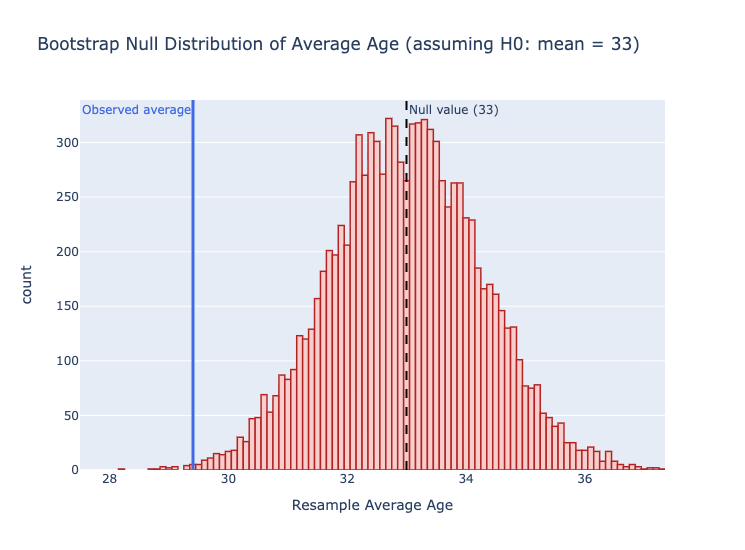

In [279]:
# Visualize the null distribution and the observed test statistic
fig = px.histogram(null_means,
                   title = "Bootstrap Null Distribution of Average Age (assuming H0: mean = 33)",
                   labels = {"value":"Resample Average Age"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC",
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

fig.add_vline(x = null_value,
              line_width = 2,
              line_dash = "dash",
              line_color = "black",
              annotation_text = "Null value (33)",
              annotation_position = "top right")

fig.add_vline(x = observed_mean,
              line_width = 3,
              line_dash = "solid",
              line_color = "royalblue",
              annotation_text = "Observed average",
              annotation_position = "top left",
              annotation_font_color = "royalblue")

### Step 5: P-value Calculation

Since $H_A$ is two-sided, "at least as extreme" means **at least as far from 33, in either direction**, as our observed average.

So we compute how far our observed average is from 33, then determine which null averages are at least that far away. The shaded regions below show which simulated values count. 

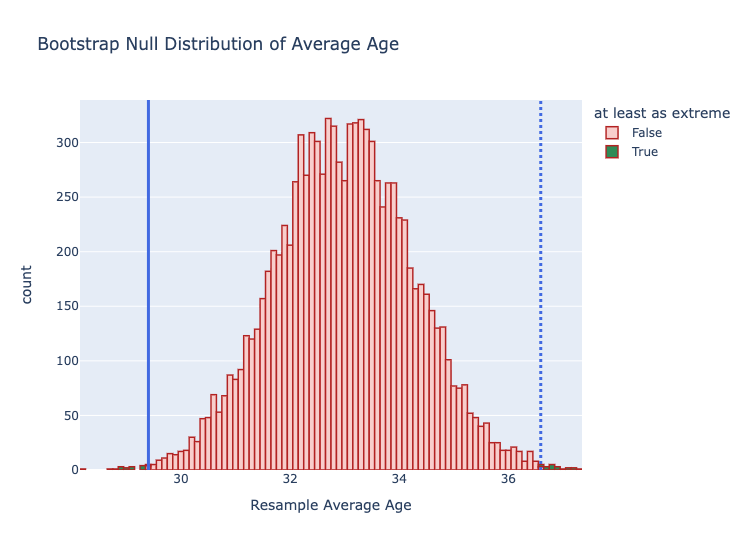

In [280]:
# How far is our observed average from the null value?
observed_distance = np.abs(observed_mean - null_value)

# Which simulated averages are at least that far from the null value (in either direction)?
null_distances = np.abs(null_means - null_value)
at_least_as_extreme = (null_distances >= observed_distance)

# Visualize which simulated values are "at least as extreme" as the observed value
results = pd.DataFrame({"null means": null_means, "at least as extreme": at_least_as_extreme})

fig = px.histogram(results, x = "null means", color = "at least as extreme",
                   title = "Bootstrap Null Distribution of Average Age",
                   labels = {"null means":"Resample Average Age"},
                   color_discrete_map = {False:"#F8CECC", True:"seagreen"},
                   height = 550)

fig.update_traces(marker_line_color = "firebrick", marker_line_width = 1.5)

fig.add_vline(x = observed_mean, line_width = 3, line_color = "royalblue")
fig.add_vline(x = null_value + (null_value - observed_mean), line_width = 3, line_dash = "dot", line_color = "royalblue")

The p-value is a **probability**: the probability of observing a test statistic at least as extreme as the one we did, if $H_0$ is true.
* We *estimate* this with a **relative frequency**.
* The relevant relative frequency is the proportion of null values we identified as being "at least as extreme": $$\text{p-value}=\frac{\text{\# of ``at least as extreme'' null values}}{N}$$ 

In [281]:
# Calculate the proportion of simulated averages that are "at least as extreme"
p_value = at_least_as_extreme.mean()
print(f"p-value: {p_value}")

p-value: 0.0035


### Step 6: Conclusion

Compare the p-value to $\alpha = 0.05$.

* You should find the p-value is very small (well below 0.05): if the true average age were 33, a random sample of 100 people with an average this far from 33 would be extremely rare.
* So we **reject $H_0$**. Our data provide strong evidence that the average age of people aboard the Titanic was *not* 33, and the museum's claim is not supported.

**How did we do?** In this case, we actually *do* have the whole population, so we can check:

In [282]:
titanic["age"].mean()

30.436734693877103

The true average age was about 30.4, not 33. Our hypothesis test, based on just 100 of the 2207 people aboard, reached the right conclusion.

---

### Connection to Confidence Intervals

At the end of last lecture we noted that a confidence interval gives a range of *plausible* values for a population attribute, and so implicitly tells us which values are *implausible*. Hypothesis testing asks whether *one particular value* is plausible. These two ideas are closely linked.

Let's calculate a 95% percentile method bootstrap confidence interval for the average age, using our *original* (unshifted) sample, exactly as we did last lecture.

In [283]:
# Bootstrap the ORIGINAL sample to get a 95% confidence interval
B = 10000
resample_means = []

for b in range(B):
    resample = S["age"].sample(n = 100, replace = True)
    resample_means.append(resample.mean())

ci_95 = np.percentile(resample_means, [2.5, 97.5])
print(f"95% confidence interval for average age: {ci_95}")
print(f"Is the null value {null_value} inside the interval? {(ci_95[0] <= null_value) & (null_value <= ci_95[1])}")

95% confidence interval for average age: [26.92857143 31.85862121]
Is the null value 33 inside the interval? False


The value 33 is outside the 95% confidence interval, so 33 is not a plausible value for the population average age. That's the same conclusion our hypothesis test reached.

This is no coincidence. In general:

> **A two-sided hypothesis test at significance level $\alpha = 0.05$ will reject $H_0$ when the null value lies *outside* the 95% confidence interval.**

* Values *inside* the 95% CI are plausible: testing any of them should give a p-value above 0.05.
* Values *outside* the 95% CI are implausible: testing any of them should give a p-value below 0.05.

More generally, a $C\%$ confidence interval pairs with a test at significance level $\alpha = 1 - C/100$:
* A 99% CI pairs with $\alpha = 0.01$,
* A 95% CI with $\alpha = 0.05$, 
* A 90% CI with $\alpha = 0.10$, and so on.

**So why bother with both?** A confidence interval tells you *the whole range* of plausible values. A hypothesis test focuses on *one specific claim* and tells you *how strong* the evidence against it is (via the p-value).

---

#### ACTIVITY 💻: Test a different claim

A history textbook claims the average age of people aboard the Titanic was **31 years**. Using the same sample `S`:

1. Carry out a bootstrap hypothesis test of $H_0$: average age $=$ 31 vs. $H_A$: average age $\neq$ 31. What is the p-value? What do you conclude at $\alpha = 0.05$?
2. Is 31 inside the 95% confidence interval we computed above? Does this agree with your test?

In [284]:
# Your code here

<details>
<summary><b>Show Solution</b></summary>

```python
null_value = 31

# Shift the sample to agree with H0
shifted_ages = S["age"] - observed_mean + null_value

# Bootstrap the shifted sample
B = 10000
null_means = []
for b in range(B):
    resample = shifted_ages.sample(n = 100, replace = True)
    null_means.append(resample.mean())
null_means = pd.Series(null_means)

# Two-sided p-value
observed_distance = np.abs(observed_mean - null_value)
p_value = (np.abs(null_means - null_value) >= observed_distance).mean()
print(f"p-value: {p_value}")

# Compare with the 95% CI
print(f"Is {null_value} inside the 95% CI? {(ci_95[0] <= null_value) & (null_value <= ci_95[1])}")
```

Most likely, the p-value is above 0.05 and 31 lies inside the 95% confidence interval, so we **fail to reject $H_0$**: the data are consistent with an average age of 31.

Notice this does *not* mean the average age *is* 31 (we know it's actually about 30.4). Many values are consistent with the data; failing to reject just means 31 is one of them.

</details>

---
---

## How Often Do We Get It Wrong?

A hypothesis test makes a decision based on random data, and the random data can fool us. So we can make mistakes when hypothesis testing. There are two kinds of mistakes:

| | $H_0$ is actually true | $H_0$ is actually false |
|---|---|---|
| **We reject $H_0$** | ❌ **Type I error** (false positive) | ✅ Correct |
| **We fail to reject $H_0$** | ✅ Correct | ❌ **Type II error** (false negative) |

In the courtroom analogy:
* A **Type I error** is convicting an innocent person.
* A **Type II error** is letting a guilty person go free.


**Ideally, we wouldn't make these errors very often. How can we control them?**

* It turns out, the significance level $\alpha$ is the probability of a Type I error!
    * If $H_0$ is true and we use $\alpha = 0.05$, we'll incorrectly reject it about 5% of the time.
    * This is the hypothesis testing version of what we saw with confidence intervals: 95% confidence intervals *miss* the truth about 5% of the time.
    * Let's check this with a simulation. We'll test a null hypothesis that we know is **true** (that the average age equals the actual population average), on $N = 100$ different random samples, and see how often we (incorrectly) reject it.

**Note:** this cell has a loop inside a loop, just like our coverage with percentile-method confidence intervals. It may take a little while to run.

In [285]:
true_mean = titanic["age"].mean()   # H0 is TRUE in this simulation
alpha = 0.05

N = 100     # number of samples (i.e., number of hypothesis tests)
B = 1000    # number of bootstrap resamples per test
rejections = []

for i in range(N):
    # Take a fresh sample from the population
    S_i = titanic.sample(n = 100)
    sample_mean = S_i["age"].mean()

    # Shift it to agree with H0, then bootstrap the null distribution
    shifted = S_i["age"] - sample_mean + true_mean
    null_means_i = []
    for b in range(B):
        resample = shifted.sample(n = 100, replace = True)
        null_means_i.append(resample.mean())
    null_means_i = pd.Series(null_means_i)

    # Two-sided p-value and decision
    p_value_i = (np.abs(null_means_i - true_mean) >= np.abs(sample_mean - true_mean)).mean()
    rejections.append(p_value_i <= alpha)

rejections = pd.Series(rejections)
print(f"Proportion of tests that (wrongly) rejected a TRUE null hypothesis: {rejections.mean()}")

Proportion of tests that (wrongly) rejected a TRUE null hypothesis: 0.05


The proportion of wrong rejections should be close to $\alpha = 0.05$. (With only $N=100$ tests it'll bounce around a bit; anything from about 0.01 to 0.10 is typical.)

**So, why not just choose a tiny $\alpha$ to avoid Type I errors?**
* Because there's a trade-off: the stricter we are about rejecting, the more often we'll *fail* to reject a null hypothesis that really is false (i.e., make a Type II error). 
* Take an extreme example: if $\alpha=0$ we would *never* reject $H_0$ and so we'll never make a Type I error. But we'll expose ourselves to potentially many more Type II errors.
    * A court that demands *absolute certainty* before convicting would rarely convict an innocent person, but it would also let many guilty people go free.

**Choosing $\alpha$ means deciding how to balance these two kinds of mistakes, and that depends on the consequences of each in the context of the problem.**

---
---

## Two-Sample Hypothesis Tests with the Bootstrap

So far, every test compared **one sample** to a **claimed value** (0.26, 0.5, 33 years). But many of the most important questions in data science involve comparing **two (or more) groups**. Does a new medication work better than a placebo? Does a new website design make users spend more?

The good news: **the logic is exactly the same.** Simulate a world in which $H_0$ is true, and see whether the real data look out of place.

---

### The Data: A/B Testing at ASOS

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/asos.png" alt="asos" width="800"/>
</div>

Recall Netflix's experimentation from our first lecture. Online controlled experiments, informally called **A/B tests**, are digital versions of randomized controlled experiments. Major tech companies run hundreds of them every day to test changes to their websites, apps, and services. If you've been on the internet today, you've probably been a subject in one of these experiments.

[ASOS.com](https://www.asos.com) is an online fashion and cosmetics retailer that targets young adults. ASOS published data from 78 experiments run on their website in 2019 and 2020. We'll analyze one of them:

* **The question:** does adding a *"free delivery"* banner to the homepage increase how much users spend? (**Disclaimer:** this is a hypothetical question).
* **The experiment:** each user who visited the homepage was *randomly* assigned to one of two versions of the site:
    * the **treatment** group (`"T"`) saw the "free delivery" banner;
    * the **control** group (`"C"`) saw the original homepage, with no mention of free delivery.
* Because assignment was random, the two groups should be alike in every way *except* the banner. So any real difference in spending can be attributed to the banner.

The experiment ran for 19 days and involved over 2 million users. We'll work with a subset of 27,694 users. For each user we have:

| Variable | Description |
|---|---|
| `Day` | Which day of the experiment (1 to 19) the user was observed |
| `Order.Value` | The total amount spent by the user (in £) |
| `Version` | `"T"` (treatment: saw the banner) or `"C"` (control: no banner) |

In [286]:
# Read in the data
asos = pd.read_csv("https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/asos.csv")
asos.head(10)

,Day,Order.Value,Version
0,1,0,C
1,1,30,C
2,1,0,C
3,1,27,C
4,1,6,C
5,1,0,C
6,1,0,C
7,1,0,C
8,1,2,C
9,1,0,C


Notice that many users spent £0: they visited the site but didn't buy anything. Let's visualize the `Order.Value` distributions in each group and compare the *average* order values.

**Note:** the question does not explicitly ask us to quantify order value using means. This is a *choice*. How might results (and insights) change if we compared a different measure of center?

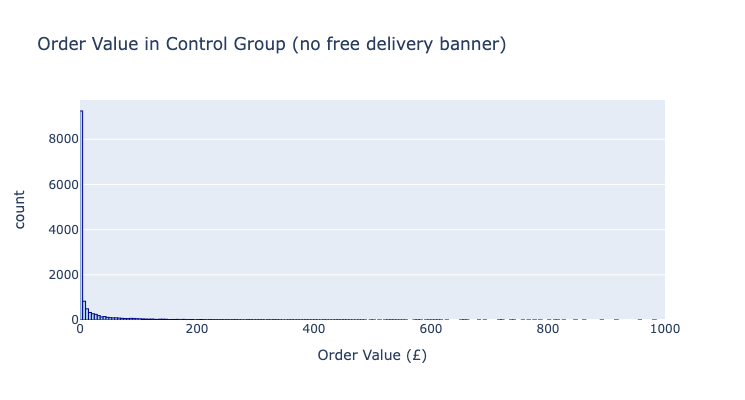

In [287]:
# Visualize the control order value distribution
fig = px.histogram(asos[asos["Version"]=="C"]["Order.Value"],
                   title = "Order Value in Control Group (no free delivery banner)",
                   labels = {"value":"Order Value (£)"},
                   height = 400, range_x = [0,1000])

fig.update_traces(showlegend = False,
                  marker_color = "lightblue", 
                  marker_line_color = "darkblue",
                  marker_line_width = 1)

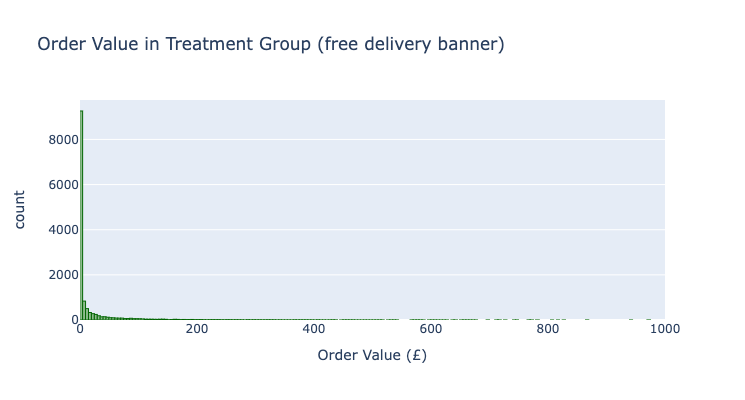

In [288]:
# Visualize the sample estimates
fig = px.histogram(asos[asos["Version"]=="T"]["Order.Value"],
                   title = "Order Value in Treatment Group (free delivery banner)",
                   labels = {"value":"Order Value (£)"},
                   height = 400, range_x = [0,1000])

fig.update_traces(showlegend = False,
                  marker_color = "darkseagreen", 
                  marker_line_color = "darkgreen",
                  marker_line_width = 1)

In [289]:
asos.groupby("Version")["Order.Value"].agg(["count", "mean"])

,count,mean
Version,,
C,13842,26.243173
T,13852,26.047863


The two averages are very close, and the treatment group actually spent slightly *less* on average. But remember: even if the banner had *no effect at all*, the two group averages wouldn't be exactly equal, just because of the random assignment of users. **Is the difference we see bigger than what chance alone would produce?**

---

### Steps 1–3: Hypotheses and Test Statistic

Let $\mathcal{P}_T$ represent the hypothetical population of users who all see a "*free delivery*" banner, and let $\mathcal{P}_C$ represent the hypothetical population of users who don't. Further, let $a(\mathcal{P}_T)$ and $a(\mathcal{P}_C)$ be the average order value in each of these populations (i.e., what average spending would be if *everyone* saw that version of the homepage).

* The *null hypothesis* is that **the banner has no effect on the average order value**. We state this as: $$H_0: a(\mathcal{P}_T) = a(\mathcal{P}_C),$$ or equivalently $$H_0: a(\mathcal{P}_T) - a(\mathcal{P}_C)=0.$$
* The *alternative hypothesis* is that **the banner *increases* average order value**. We state this as $$H_A: a(\mathcal{P}_T) > a(\mathcal{P}_C),$$ or equivalently $$H_A: a(\mathcal{P}_T) - a(\mathcal{P}_C)>0.$$
* The *test statistic* could simply be the **difference in sample averages**: $a(\mathcal{S}_T) - a(\mathcal{S}_C)$, where $\mathcal{S}_T$ and $\mathcal{S}_C$ represent the observed treatment and control data.
    * *Large* values favour $H_A$.

**Notice:** the null hypothesis is still a claim about *one* attribute, the difference in means, and the null value is 0.

In [294]:
# Split the data into the two groups
S_T = asos[asos["Version"] == "T"]["Order.Value"]
S_C   = asos[asos["Version"] == "C"]["Order.Value"]

observed_diff = S_T.mean() - S_C.mean()
print(f"Observed difference in average order value (T - C): {observed_diff}")

Observed difference in average order value (T - C): -0.1953098274270033


### Step 4: Simulating the Null Distribution with the Bootstrap

We use the same trick as in the one-sample test: **shift the data so that $H_0$ is true, then bootstrap.**

* In the one-sample test, we shifted our sample so its average was exactly the null value (33).
* Now, $H_0$ says the two groups have the *same* average. So we shift **both** groups so that their averages equal the **overall** average of all users combined. Each group keeps its own spread and shape, but now their averages agree, just as $H_0$ claims.

Then we bootstrap: resample **each group separately** (with replacement, keeping the group sizes the same), and calculate the difference in averages each time.

In [295]:
# Shift both groups so they have the same average (the overall average), so H0 is true
overall_mean = asos["Order.Value"].mean()
shifted_treatment = S_T - S_T.mean() + overall_mean
shifted_control   = S_C - S_C.mean() + overall_mean

print(f"Shifted treatment average: {shifted_treatment.mean()}")
print(f"Shifted control average:   {shifted_control.mean()}")

Shifted treatment average: 26.145482776052578
Shifted control average:   26.14548277605257


In [296]:
# Bootstrap each shifted group B = 10,000 times, recording the difference in averages each time
B = 10000
null_diffs = []

for b in range(B):
    resample_T = shifted_treatment.sample(n = len(S_T), replace = True)
    resample_C = shifted_control.sample(n = len(S_C), replace = True)
    null_diffs.append(resample_T.mean() - resample_C.mean())

null_diffs = pd.Series(null_diffs)

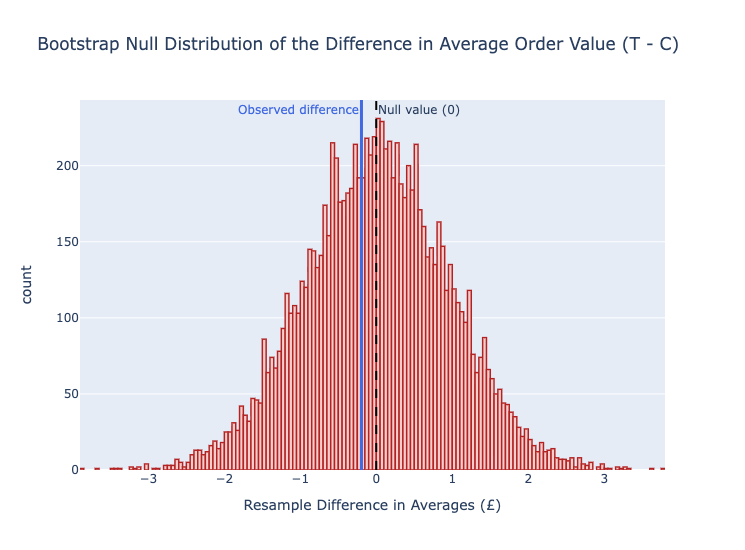

In [297]:
# Visualize the null distribution and the observed test statistic
fig = px.histogram(null_diffs,
                   title = "Bootstrap Null Distribution of the Difference in Average Order Value (T - C)",
                   labels = {"value":"Resample Difference in Averages (£)"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC",
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

fig.add_vline(x = 0,
              line_width = 2,
              line_dash = "dash",
              line_color = "black",
              annotation_text = "Null value (0)",
              annotation_position = "top right")

fig.add_vline(x = observed_diff,
              line_width = 3,
              line_dash = "solid",
              line_color = "royalblue",
              annotation_text = "Observed difference",
              annotation_position = "top left",
              annotation_font_color = "royalblue")

### Step 5: P-value Calculation

Our alternative hypothesis is one-sided $H_A: a(\mathcal{P}_T) > a(\mathcal{P}_C)$, so "at least as extreme" means **at least as large as** the observed difference.

In [298]:
p_value = (null_diffs >= observed_diff).mean()
print(f"p-value: {p_value}")

p-value: 0.5884


### Step 6: Conclusion

The p-value is large (well above 0.05). The observed difference sits right in the middle of the null distribution: it's exactly the kind of difference we'd expect from random assignment alone, even if the banner did nothing. So we **fail to reject $H_0$**. These data provide no evidence that the "*free delivery*" banner increases average order value.

Remember what "fail to reject" means: this doesn't *prove* the banner has no effect. A 95% bootstrap confidence interval for $a(\mathcal{P}_T) - a(\mathcal{P}_C)$ tells us what size of effect is still plausible:

In [300]:
# Bootstrap the ORIGINAL (unshifted) groups to get a 95% CI for the difference in averages
B = 10000
resample_diffs = []

for b in range(B):
    resample_T = S_T.sample(n = len(S_T), replace = True)
    resample_C = S_C.sample(n = len(S_C), replace = True)
    resample_diffs.append(resample_T.mean() - resample_C.mean())

np.percentile(resample_diffs, [2.5, 97.5])

array([-2.05612219,  1.65300472])

The interval contains 0, consistent with our test. It suggests that if the banner has any effect at all, it's likely somewhere between a small decrease and a small increase of a couple of pounds per user. For ASOS, that's useful information: the banner probably isn't worth much, and that's exactly the kind of decision A/B tests are designed to inform.

**What's the same, and what changed, compared to the one-sample test?**

| | One-sample (Titanic) | Two-sample (ASOS) |
|---|---|---|
| Attribute | average age | difference in average order value |
| $H_0$ | average age $= 33$ | difference $= 0$ |
| Making $H_0$ true | shift the sample to have average 33 | shift both groups to have the same average |
| Bootstrap | resample the one sample | resample each group separately |
| p-value | proportion of null values at least as extreme as observed test statistic| $\leftarrow$ the same! |

---

#### ACTIVITY 💻: Repeat the test above, but compare *median* order value

---
---

## Key Takeaways

* A **hypothesis test** assesses whether data are consistent with a specific claim (the **null hypothesis** $H_0$) about a population or a chance process.
* The core idea: **simulate what the data would look like if $H_0$ were true**, and compare this to the data you actually observe.
    * If $H_0$ fully describes the chance process (e.g., Robert Swain, Paul the Octopus), we can simulate directly with `np.random.choice()`.
    * If $H_0$ only specifies one attribute (e.g., a mean), we can **shift our sample to agree with $H_0$ and bootstrap it**.
    * The same idea extends to **comparing two groups** (e.g., an A/B test): shift both groups to have the same average, then bootstrap each group separately.
* The **p-value** is the probability, assuming $H_0$ is true, of a test statistic at least as extreme as the one observed. We estimate this probability with a relative frequency.
* Small p-values are evidence against $H_0$. 
    * We **reject $H_0$** if the p-value $\le \alpha$ (often 0.05), and otherwise **fail to reject** it. Failing to reject is *not* proof that $H_0$ is true.
* A p-value is **not** the probability that $H_0$ is true, and statistical significance is **not** the same as practical importance.
* Two-sided tests and confidence intervals have a direct connection: a test at $\alpha=0.05$ rejects (approximately) when the null value falls outside the 95% CI.
* Tests can make **Type I** (false positive) and **Type II** (false negative) errors. The significance level $\alpha$ is the Type I error rate.
* In *Swain v. Alabama*, a simple simulation shows that what the Supreme Court called a "small" disparity was, in fact, overwhelming evidence of a biased selection process. **Quantifying uncertainty protects us from relying on gut feelings, which can be wrong, and can be biased.**

---
---